In [7]:
import pandas as pd
import numpy as np
import math

np.random.seed(42)
n_users = 50000


group_assignments = np.random.choice(['control', 'treatment'], size=n_users, p=[0.5, 0.5])

converted_control = np.random.binomial(1, 0.120, size=np.sum(group_assignments == 'control'))
converted_treatment = np.random.binomial(1, 0.128, size=np.sum(group_assignments == 'treatment'))

converted = np.zeros(n_users, dtype=int)
converted[group_assignments == 'control'] = converted_control
converted[group_assignments == 'treatment'] = converted_treatment

df_ab = pd.DataFrame({
    'user_id': [100000 + i for i in range(n_users)],
    'group': group_assignments,
    'converted': converted
})


ab_summary = df_ab.groupby('group').agg(
    total_users=('converted', 'count'),
    total_conversions=('converted', 'sum'),
    conversion_rate=('converted', 'mean')
).reset_index()

ab_summary['conversion_rate (%)'] = ab_summary['conversion_rate'] * 100

print("=== 📊 خلاصه عملکرد گروه‌های تست A/B ===")
print(ab_summary.round(3).to_string(index=False))


n_ctrl = ab_summary.loc[ab_summary['group'] == 'control', 'total_users'].values[0]
n_trtm = ab_summary.loc[ab_summary['group'] == 'treatment', 'total_users'].values[0]
p_ctrl = ab_summary.loc[ab_summary['group'] == 'control', 'conversion_rate'].values[0]
p_trtm = ab_summary.loc[ab_summary['group'] == 'treatment', 'conversion_rate'].values[0]

p_pooled = (p_ctrl * n_ctrl + p_trtm * n_trtm) / (n_ctrl + n_trtm)
se = math.sqrt(p_pooled * (1 - p_pooled) * (1/n_ctrl + 1/n_trtm))
z_score = (p_trtm - p_ctrl) / se


def norm_cdf(z):
    return (1.0 + math.erf(z / math.sqrt(2.0))) / 2.0

p_value = 2 * (1 - norm_cdf(abs(z_score)))

print("\n=== 🧪 نتایج تحلیل آماری (Z-Test) ===")
print(f"Z-Score: {z_score:.4f}")
print(f"p-value: {p_value:.5f}")

if p_value < 0.05:
    print("نتیجه: تغییر معنادار است! (تفاوت نرخ تبدیل با اطمینان ۹۵٪ اتفاقی نیست)")
else:
    print("نتیجه: تغییر معنادار نیست.")

=== 📊 خلاصه عملکرد گروه‌های تست A/B ===
    group  total_users  total_conversions  conversion_rate  conversion_rate (%)
  control        25053               2938            0.117               11.727
treatment        24947               3112            0.125               12.474

=== 🧪 نتایج تحلیل آماری (Z-Test) ===
Z-Score: 2.5619
p-value: 0.01041
نتیجه: تغییر معنادار است! (تفاوت نرخ تبدیل با اطمینان ۹۵٪ اتفاقی نیست)


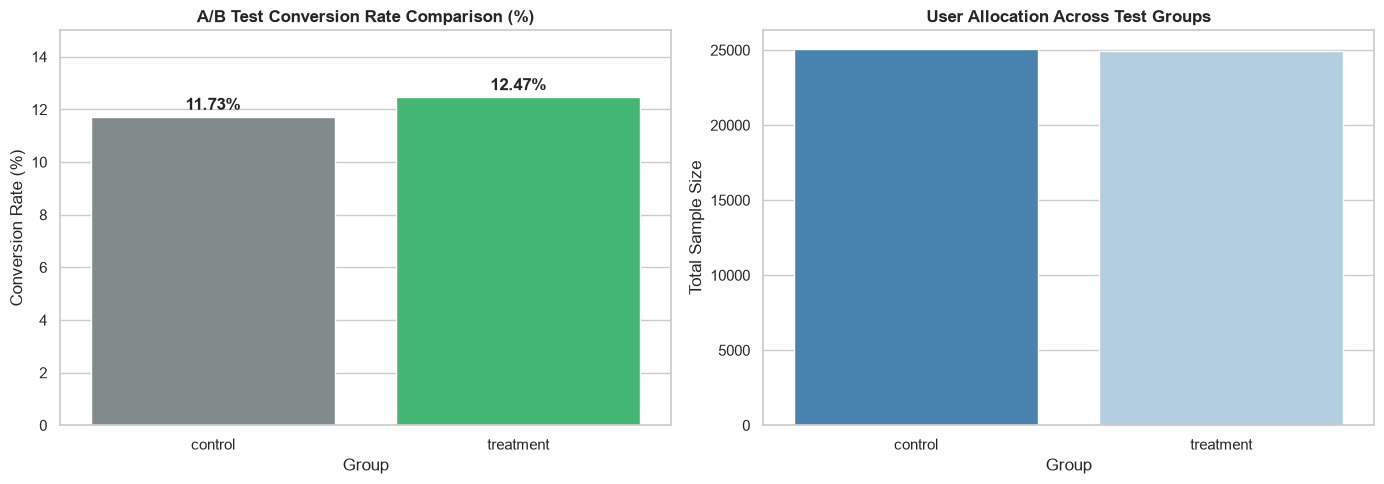

In [8]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(1, 2, figsize=(14, 5))


sns.barplot(
    ax=axes[0], 
    data=ab_summary, 
    x='group', 
    y='conversion_rate (%)', 
    hue='group', 
    palette=['#7f8c8d', '#2ecc71'], 
    legend=False
)
axes[0].set_title('A/B Test Conversion Rate Comparison (%)', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Group')
axes[0].set_ylabel('Conversion Rate (%)')
axes[0].set_ylim(0, 15)


for p in axes[0].patches:
    axes[0].annotate(f'{p.get_height():.2f}%', 
                    (p.get_x() + p.get_width() / 2., p.get_height()), 
                    ha='center', va='center', 
                    xytext=(0, 8), 
                    textcoords='offset points', 
                    fontweight='bold')


sns.barplot(
    ax=axes[1], 
    data=ab_summary, 
    x='group', 
    y='total_users', 
    hue='group', 
    palette='Blues_r', 
    legend=False
)
axes[1].set_title('User Allocation Across Test Groups', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Group')
axes[1].set_ylabel('Total Sample Size')

plt.tight_layout()
plt.show()